<a href="https://colab.research.google.com/github/Andressuz2460/Optativa_II_TDS/blob/main/01_regresion_lineal_parte1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tu primer modelo de Machine Learning: regresión lineal

**Clase práctica · Nivel inicial · Google Colab**

En este ejercicio aprenderemos a predecir una **nota final** usando información de estudiantes **ficticios**. Primero subiremos un archivo CSV; después conoceremos los datos, entrenaremos un modelo, revisaremos sus errores y haremos predicciones.

**Materiales:** este notebook `.ipynb` y el archivo `rendimiento-estudiantes-SIMULADO.csv` que se entregan juntos. **Estos datos son inventados para practicar y no representan estudiantes reales.**

**Importante:** ejecuta las celdas de arriba hacia abajo, leyendo las explicaciones antes de hacer clic en ▶. Ninguna celda descarga datos de GitHub.

## 1. Dos archivos distintos: el notebook y la base de datos

En esta clase utilizaremos **dos archivos** y cada uno se sube de manera diferente:

| Archivo | ¿Qué contiene? | ¿Cómo lo usamos? |
|---|---|---|
| `01-regresion-lineal-Colab-EXPLICADO-CON-CSV.ipynb` | Las explicaciones y el código de Python | Se abre en Google Colab desde **Archivo → Subir notebook**. |
| `rendimiento-estudiantes-SIMULADO.csv` | Los **400 estudiantes ficticios** con cinco variables | Se carga **dentro del notebook**, ejecutando la siguiente celda de Python. |

### Cómo cargar correctamente el CSV desde tu Mac

**Paso 1.** Descarga ambos archivos y abre el `.ipynb` en https://colab.research.google.com/. Si la ventana solo muestra notebooks `.ipynb`, es normal: **esa ventana no sirve para subir el CSV**.

**Paso 2.** Asegúrate de que el CSV esté en **Finder → Descargas**. Puede llamarse `rendimiento-estudiantes-SIMULADO.csv` o `rendimiento-estudiantes-SIMULADO (1).csv` si lo descargaste más de una vez. **No elijas el archivo `.xlsx`**: es un archivo de Excel diferente.

**Paso 3.** **Cierra la ventana de “Subir notebook”** si está abierta. Dentro del notebook, busca la celda de código que aparece justo debajo de estas instrucciones y presiona su botón **▶**. La celda ejecuta `files.upload()`: aparecerá un botón **Elegir archivos**, distinto de la ventana anterior.

**Paso 4.** Pulsa **Elegir archivos → Descargas → selecciona el `.csv` → Abrir**. No necesitas copiarlo ni cambiarle la extensión. Si no aparece, revisa que hayas ejecutado `files.upload()` dentro de una celda y no `Archivo → Subir notebook`.

**Paso 5.** La celda mostrará el **nombre del archivo recibido**. El programa aceptará automáticamente nombres con `(1)` y guardará su ubicación en `RUTA_DATOS`. Después, en la sección 3, verificaremos que hay **400 filas y 5 columnas**.

> **Si Google Colab se reinicia:** los archivos subidos al entorno temporal pueden desaparecer. Simplemente ejecuta nuevamente la celda para subir el CSV.

### ¿Qué aprenderemos con este paso?

`files.upload()` permite seleccionar un archivo **desde el computador**. `pd.read_csv()` lo leerá después. **Subir el archivo y leerlo son dos acciones diferentes.** El notebook no necesita descargar datos desde GitHub.

In [ ]:
# PASO 1. SUBIR LA BASE DE DATOS CSV DESDE EL COMPUTADOR
# Esta celda NO abre un notebook: pide el archivo de datos (.csv).

# Path nos permite trabajar con nombres y ubicaciones de archivos.
from pathlib import Path

# Este es el nombre principal del archivo que entregamos a la clase.
NOMBRE_CSV = "rendimiento-estudiantes-SIMULADO.csv"

# Si el CSV ya fue subido y ejecutamos nuevamente la celda,
# utilizaremos el archivo existente sin pedir que se suba otra vez.
RUTA_DATOS = Path(NOMBRE_CSV)

if not RUTA_DATOS.is_file():
    # Colab tiene una herramienta especial para recibir archivos de tu Mac.
    # Si se usa VS Code, en su lugar se necesita poner el CSV junto al notebook.
    try:
        from google.colab import files
    except ImportError:
        # En un computador local podemos utilizar incluso una copia "(1).csv".
        opciones = sorted(Path('.').glob('rendimiento-estudiantes-SIMULADO*.csv'))
        if not opciones:
            raise FileNotFoundError(
                "No encuentro el CSV. Guárdalo en la carpeta de trabajo y vuelve a ejecutar."
            )
        RUTA_DATOS = opciones[0]
    else:
        print("AHORA SUBE EL CSV, NO EL NOTEBOOK .ipynb")
        print("Haz clic en 'Elegir archivos', abre Descargas y selecciona el archivo .csv.")
        print("Si descargaste varias copias, también sirve el nombre que termina en (1).csv.")

        # Esta instrucción abre el selector de archivos de tu computador.
        archivos_subidos = files.upload()

        # files.upload() devuelve los nombres de los archivos que recibimos.
        # Aceptamos el CSV original y copias con (1), (2), etc.
        candidatos = [nombre for nombre in archivos_subidos
                      if Path(nombre).name.startswith('rendimiento-estudiantes-SIMULADO')
                      and Path(nombre).suffix.lower() == '.csv']
        if not candidatos:
            raise ValueError(
                "No se recibió el CSV correcto. Ejecuta de nuevo esta celda, "
                "pulsa 'Elegir archivos' y selecciona rendimiento-estudiantes-SIMULADO.csv; "
                "no selecciones archivos .ipynb ni .xlsx."
            )
        # Elegimos el archivo que acabamos de subir y guardamos su ubicación.
        RUTA_DATOS = Path(candidatos[0])

# Antes de continuar confirmamos que el archivo existe de verdad.
if not RUTA_DATOS.is_file():
    raise FileNotFoundError("No se encontró el archivo CSV seleccionado.")

print("¡Archivo CSV preparado correctamente!")
print("Nombre elegido:", RUTA_DATOS.name)
print("Ubicación:", RUTA_DATOS.resolve())
print("En la sección 3 leeremos el CSV y veremos sus primeros registros.")

AHORA SUBE EL CSV, NO EL NOTEBOOK .ipynb
Haz clic en 'Elegir archivos', abre Descargas y selecciona el archivo .csv.
Si descargaste varias copias, también sirve el nombre que termina en (1).csv.


## 2. Preparar nuestras herramientas

**¿Qué hacemos?** Pedimos a Python herramientas para leer tablas, calcular, dibujar gráficas y entrenar un modelo de regresión lineal.

- `pandas` (`pd`): trabaja con tablas, como las de Excel.
- `numpy` (`np`): realiza operaciones matemáticas.
- `matplotlib.pyplot` (`plt`): permite crear gráficas.
- `LinearRegression`: encuentra una ecuación para estimar notas.
- `DummyRegressor`: es un modelo muy básico para comparar.
- `train_test_split`: separa estudiantes para aprender y para evaluar.
- `mean_absolute_error`, `mean_squared_error` y `r2_score`: miden qué tan acertadas son las predicciones.

**¿Qué es `SEMILLA = 42`?** Un número que utilizaremos para repetir la misma división aleatoria de los datos. No significa 42 estudiantes ni 42 intentos.

In [ ]:
# Herramienta para construir gráficas.
import matplotlib.pyplot as plt

# Herramienta para operaciones numéricas (por ejemplo, raíces cuadradas).
import numpy as np

# Herramienta para leer CSV y manejar tablas con filas y columnas.
import pandas as pd

# Modelo de referencia: predice siempre la nota media del entrenamiento.
from sklearn.dummy import DummyRegressor

# Algoritmo con el que entrenaremos la regresión lineal.
from sklearn.linear_model import LinearRegression

# Medidas para evaluar la calidad de las predicciones.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Función para dividir nuestros datos entre entrenamiento y prueba.
from sklearn.model_selection import train_test_split

# Usaremos el mismo número para reproducir la división de los datos.
SEMILLA = 42
print("Herramientas listas para trabajar.")

Herramientas listas para trabajar.


## 3. Leer el CSV y conocer sus dimensiones

**Primero lo subimos; ahora lo abrimos.** La celda anterior almacenó su ubicación en `RUTA_DATOS`. Con `pd.read_csv(RUTA_DATOS)` pedimos a **pandas** que lea el archivo y cree una tabla llamada `datos`.

- `datos`: nombre que utilizaremos en Python para referirnos a la tabla completa.
- `pd.read_csv(...)`: abre un archivo de texto de valores separados por comas (CSV).
- `print(...)`: escribe mensajes en pantalla.
- `datos.shape[0]`: número de **filas** (registros o estudiantes ficticios).
- `datos.shape[1]`: número de **columnas** (variables).
- `datos.head()`: enseña las **primeras cinco filas**; no borra las demás.

**Resultado esperado:** `Filas: 400 · Columnas: 5`. Si aparece un número diferente, revisa el nombre y contenido del archivo que subiste. **No necesitamos abrir el CSV en Excel para usarlo en Colab.**

In [ ]:
# PASO 2. LEER EL CSV QUE SELECCIONAMOS EN LA CELDA ANTERIOR
# pd es el nombre corto de la biblioteca pandas, importada en la sección 2.
# read_csv lee el archivo señalado por RUTA_DATOS (aunque tenga "(1)" en el nombre).
# El resultado es un DataFrame: una tabla de filas y columnas llamada "datos".
datos = pd.read_csv(RUTA_DATOS)

# shape significa "dimensiones de la tabla".
# [0] indica la posición de las FILAS y [1] la de las COLUMNAS.
# La letra f permite insertar el valor de esos cálculos dentro del mensaje.
print(f"Filas: {datos.shape[0]} · Columnas: {datos.shape[1]}")

# Comprobamos que estamos usando la base preparada para esta clase.
# Si no coincide, avisamos claramente y evitamos seguir con datos incorrectos.
if datos.shape != (400, 5):
    raise ValueError("La base esperada tiene 400 filas y 5 columnas. Revisa el CSV cargado.")

# head(5) muestra los primeros cinco registros para que podamos reconocer
# qué contiene cada columna. No modifica ni elimina la tabla original.
display(datos.head(5))

Filas: 400 · Columnas: 5


,promedio_anterior,horas_estudio_semana,asistencia_pct,trabaja,nota_final
0,3.76,8.3,72.7,0,3.48
1,3.05,9.8,70.1,0,3.07
2,4.00,12.3,85.8,0,4.21
3,4.10,7.4,86.2,0,3.54
4,2.57,11.1,96.2,1,2.86


### Si el CSV no aparece en el selector de archivos

1. **Comprueba en Finder** que el archivo está en **Descargas** y termina exactamente en `.csv`. Si ves un `.xlsx`, no es el archivo para esta actividad.
2. **No utilices “Archivo → Subir notebook”** para cargar datos: ese menú busca archivos `.ipynb` y puede ocultar los `.csv`.
3. **Vuelve a ejecutar la celda de la sección 1**, donde está escrito `files.upload()`. Haz clic en **Elegir archivos** debajo de esa celda.
4. Si ves dos archivos como `rendimiento-estudiantes-SIMULADO.csv` y `rendimiento-estudiantes-SIMULADO (1).csv`, **cualquiera de los dos sirve**. El código reconoce el nombre seleccionado.
5. Si Colab dice que no encuentra el archivo, **ejecuta las celdas desde el principio y en orden**. Una sesión reiniciada borra los archivos temporales.

**Comprobación sencilla:** la celda de carga debe mostrar `¡Archivo CSV preparado correctamente!` y la de lectura debe mostrar `Filas: 400 · Columnas: 5`. Si ambas aparecen, puedes continuar con el modelo.

## 4. Entender qué significa cada variable

| Variable en Python | Explicación comprensible | Unidad |
|---|---|---|
| `promedio_anterior` | Promedio que el estudiante había obtenido antes | Nota entre 0 y 5 |
| `horas_estudio_semana` | Tiempo que dedica a estudiar durante una semana | Horas |
| `asistencia_pct` | Porcentaje de clases a las que asiste | Porcentaje entre 0 y 100 |
| `trabaja` | Si tiene trabajo: `1` sí, `0` no | Indicador binario |
| `nota_final` | Nota que queremos que el modelo aprenda a predecir | Nota entre 0 y 5 |

**Importante:** estas asociaciones se establecieron artificialmente para practicar, no prueban que una característica cause una nota determinada.

## 5. Verificar tipos de datos y faltantes

Antes de entrenar conviene revisar que las columnas tengan números y no haya celdas vacías. `info()` identifica tipos y valores no nulos; `isna().sum()` cuenta vacíos por columna.

**¿Qué buscamos?** Que cada columna tenga 400 valores no nulos y que el conteo de faltantes sea 0. Esta base es limpia intencionalmente, aunque muchas bases reales no lo son.

In [ ]:
# Mostramos nombre, cantidad de valores presentes y tipo de cada columna.
print("ESTRUCTURA DE LA TABLA")
datos.info()

# isna() identifica valores vacíos; sum() cuenta cuántos hay por columna.
print("\nVALORES FALTANTES POR COLUMNA")
print(datos.isna().sum())

# Comprobamos que están las cinco variables necesarias.
columnas_necesarias = ["promedio_anterior", "horas_estudio_semana", "asistencia_pct", "trabaja", "nota_final"]
if not set(columnas_necesarias).issubset(datos.columns):
    raise ValueError("El CSV no tiene todas las columnas necesarias para el ejercicio.")

ESTRUCTURA DE LA TABLA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   promedio_anterior     400 non-null    float64
 1   horas_estudio_semana  400 non-null    float64
 2   asistencia_pct        400 non-null    float64
 3   trabaja               400 non-null    int64  
 4   nota_final            400 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 15.8 KB

VALORES FALTANTES POR COLUMNA
promedio_anterior       0
horas_estudio_semana    0
asistencia_pct          0
trabaja                 0
nota_final              0
dtype: int64


## 6. Resumir los datos con estadística descriptiva

`describe()` presenta el número de datos, media, desviación estándar, mínimo, cuartiles y máximo. `round(2)` muestra solo dos decimales.

**Ejemplo de interpretación:** si la media de `horas_estudio_semana` se acerca a 9, indica que el promedio de horas de estudio de esta base ficticia ronda nueve horas semanales. **No significa que todos estudien nueve horas.**

In [ ]:
# Calculamos estadísticas de cada columna numérica.
# count = número de valores; mean = promedio; std = dispersión.
# min y max = valores extremos; 25%, 50%, 75% = cuartiles.
# round(2) deja la visualización con dos decimales.
datos.describe().round(2)

,promedio_anterior,horas_estudio_semana,asistencia_pct,trabaja,nota_final
count,400.00,400.00,400.00,400.00,400.00
mean,3.60,8.81,81.72,0.38,3.33
std,0.50,4.02,10.38,0.49,0.43
min,2.24,0.00,50.00,0.00,1.96
25%,3.25,5.90,75.35,0.00,3.03
50%,3.61,8.85,82.10,0.00,3.35
75%,3.91,11.50,88.72,1.00,3.61
max,4.90,19.40,100.00,1.00,4.52


## 7. Definir la pregunta de predicción

Queremos **predecir `nota_final`** a partir de cuatro datos que sí conocemos.

- **X** (mayúscula): tabla con las cuatro columnas que ayudan a predecir; se llaman *características* o *variables explicativas*.
- **y** (minúscula): columna que contiene la respuesta que el modelo intentará calcular; se llama *variable objetivo*.

**Analogía:** si quisiéramos predecir el precio de una vivienda, X serían área, habitaciones y ubicación, mientras y sería el precio. Aquí la respuesta es una nota, no un precio.

In [ ]:
# Indicamos los nombres de las cuatro columnas que usará el modelo.
caracteristicas = ["promedio_anterior", "horas_estudio_semana", "asistencia_pct", "trabaja"]

# Indicamos el nombre de la columna cuyo valor queremos predecir.
objetivo = "nota_final"

# X contiene las variables que sirven como entrada al modelo.
X = datos[caracteristicas]

# y contiene las notas reales: la respuesta que queremos aprender.
y = datos[objetivo]

# Mostramos dimensiones: X tiene 400 filas y 4 columnas;
# y tiene 400 valores, uno para cada estudiante ficticio.
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (400, 4)
Dimensiones de y: (400,)


## 8. Separar los datos: entrenamiento y prueba

**¿Por qué separarlos?** Si enseñamos al modelo usando todos los estudiantes y luego lo examinamos con esos mismos estudiantes, la evaluación puede dar una impresión demasiado optimista.

`test_size=0.20` reserva **20 % para prueba (80 estudiantes)** y deja **80 % para entrenamiento (320 estudiantes)**.

`random_state=SEMILLA` utiliza la misma semilla (42) para repetir la división.

**Regla:** el conjunto de prueba no participa en el entrenamiento.

In [ ]:
# Dividimos X (entradas) y y (notas) manteniendo las parejas correctas.
# 0.20 significa que el 20 % de los registros será para examen.
# SEMILLA hace que la selección aleatoria sea reproducible.
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)

# Confirmamos cuántos estudiantes ficticios quedaron en cada grupo.
print(f"Entrenamiento: {len(X_entrena)} estudiantes")
print(f"Prueba: {len(X_prueba)} estudiantes")

Entrenamiento: 320 estudiantes
Prueba: 80 estudiantes


## 9. Entrenar un modelo de regresión lineal

**¿Qué es una regresión lineal?** Un procedimiento que busca una ecuación aproximada para relacionar varias entradas con una respuesta numérica.

`LinearRegression()` crea el modelo *vacío*, y `fit(X_entrena, y_entrena)` le permite estimar los números de su ecuación utilizando los 320 ejemplos de entrenamiento.

**¡Atención!** Que aparezca «Modelo entrenado» no significa que prediga bien. Lo verificaremos después.

In [ ]:
# Creamos un modelo de regresión lineal que aún no conoce datos.
modelo = LinearRegression()

# Lo entrenamos: las cuatro características son las entradas (X),
# y la nota final conocida es la respuesta correcta (y).
modelo.fit(X_entrena, y_entrena)

# Este mensaje solo confirma que terminó el entrenamiento.
print("Modelo entrenado. Falta evaluar qué tan bien predice.")

## 10. Interpretar los coeficientes del modelo

El modelo aprendió una ecuación aproximada:

**Nota predicha = intercepto + coeficiente₁ × promedio + coeficiente₂ × horas + coeficiente₃ × asistencia + coeficiente₄ × trabaja.**

`coef_` da un coeficiente por variable; `intercept_` es el valor de partida de la ecuación. Un coeficiente indica el cambio *estimado* de la nota ante una unidad adicional de esa variable, **manteniendo las demás constantes**.

**Ejemplo:** un coeficiente cercano a `0.055` para horas implicaría una diferencia estimada de 0.055 puntos por una hora semanal más, sin cambiar las demás variables. No demuestra causalidad.

In [ ]:
# Construimos una tabla con el nombre de cada variable y su coeficiente.
coeficientes = pd.DataFrame({
    "caracteristica": caracteristicas,
    "coeficiente": modelo.coef_.round(4)
})

# Mostramos el término constante de la ecuación (intercepto).
print(f"Intercepto estimado: {modelo.intercept_:.4f}\n")

# Mostramos los coeficientes aprendidos por el algoritmo.
print(coeficientes.to_string(index=False))

Intercepto estimado: -0.0880

      caracteristica  coeficiente
   promedio_anterior       0.5900
horas_estudio_semana       0.0609
      asistencia_pct       0.0104
             trabaja      -0.2531


## 11. Comparar los coeficientes aprendidos con los de nuestra simulación

**Este paso solo es posible porque creamos artificialmente los datos.** Usamos una fórmula de referencia con intercepto `-0.17` y los pesos `0.62`, `0.055`, `0.011` y `-0.22`, a los que añadimos variación aleatoria. Redondeamos las notas y aplicamos un límite de 0 a 5.

El modelo **no recibió** esos coeficientes durante el entrenamiento; intenta estimarlos. Por la variación aleatoria, el redondeo y el límite de notas, **no esperamos que coincidan exactamente**.

La columna `diferencia` indica *estimado − usado en la simulación*. Una diferencia pequeña es compatible con una estimación cercana.

In [ ]:
# Estos números son parámetros usados al fabricar nuestra base ficticia.
# NO son reglas universales del rendimiento académico.
coeficientes_simulacion = {
    "promedio_anterior": 0.62,
    "horas_estudio_semana": 0.055,
    "asistencia_pct": 0.011,
    "trabaja": -0.22
}

# Unimos los coeficientes de generación y los estimados por el modelo.
comparacion = pd.DataFrame({
    "caracteristica": caracteristicas,
    "simulado": [coeficientes_simulacion[c] for c in caracteristicas],
    "estimado": modelo.coef_
})

# Restamos para ver qué tan cerca quedó el ajuste.
comparacion["diferencia"] = comparacion["estimado"] - comparacion["simulado"]

# Redondeamos solo para facilitar la lectura de la tabla.
print(comparacion.round(4).to_string(index=False))

      caracteristica  simulado  estimado  diferencia
   promedio_anterior     0.620    0.5900     -0.0300
horas_estudio_semana     0.055    0.0609      0.0059
      asistencia_pct     0.011    0.0104     -0.0006
             trabaja    -0.220   -0.2531     -0.0331


## 12. Predecir notas que el modelo no vio durante el entrenamiento

`predict(X_prueba)` pide al modelo que estime las notas de los **80 estudiantes de prueba**. Luego mostramos una tabla con 10 de ellos para observar si estuvo cerca.

Definimos **error = nota predicha − nota real**: error positivo es *sobreestimación*; error negativo es *subestimación*. Por ejemplo, predecir 4.2 cuando la nota real es 4.0 produce un error de +0.2.

**Importante:** un error de 0 no garantiza que las demás predicciones sean perfectas.

In [ ]:
# Pedimos predicciones para estudiantes que no se usaron en el ajuste.
y_predicho = modelo.predict(X_prueba)

# Construimos una tabla con las notas reales y predichas.
# Usamos las 80 observaciones, aunque solo mostraremos 10.
resultados = pd.DataFrame({
    "nota_real": y_prueba.to_numpy(),
    "nota_predicha": y_predicho
})

# Error firmado: predicción menos valor real.
resultados["error"] = resultados["nota_predicha"] - resultados["nota_real"]

# Mostramos los primeros diez casos con dos decimales.
print(resultados.head(10).round(2).to_string(index=False))

 nota_real  nota_predicha  error
      3.17           3.51   0.34
      3.96           3.81  -0.15
      2.94           2.69  -0.25
      3.25           3.08  -0.17
      3.69           3.53  -0.16
      2.66           2.93   0.27
      2.58           2.76   0.18
      2.49           2.55   0.06
      3.28           2.96  -0.32
      3.90           3.98   0.08


## 13. Evaluar qué tan buenas son las predicciones

No es suficiente mirar diez casos. Mediremos **todos los casos de prueba** con tres indicadores:

- **MAE, error absoluto medio:** cuántos puntos de nota se equivoca el modelo, en promedio, sin importar el signo. **Menor es mejor.**
- **RMSE, raíz del error cuadrático medio:** parecido al MAE, pero penaliza más los errores grandes. **Menor es mejor.**
- **R², coeficiente de determinación:** compara el error cuadrático del modelo contra el de predecir siempre la media de las notas de prueba. **1 es perfecto; 0 equivale a esa referencia y puede ser negativo.**

**Pregunta:** si el MAE fuera 0.20, ¿qué significaría? Que el error absoluto promedio en la escala de notas es de 0.20 puntos. No quiere decir que todos se equivocaron exactamente 0.20.

In [ ]:
# Calculamos cuánto se equivoca, en promedio, sin usar el signo (MAE).
mae = mean_absolute_error(y_prueba, y_predicho)

# Calculamos el error cuadrático promedio y sacamos su raíz (RMSE).
# np.sqrt significa 'raíz cuadrada'.
rmse = np.sqrt(mean_squared_error(y_prueba, y_predicho))

# Calculamos R² para evaluar el ajuste predictivo en el grupo de prueba.
r2 = r2_score(y_prueba, y_predicho)

# Mostramos los tres resultados; el formato .3f usa tres decimales.
print(f"MAE : {mae:.3f} puntos de nota")
print(f"RMSE: {rmse:.3f} puntos de nota")
print(f"R²  : {r2:.3f}")

MAE : 0.150 puntos de nota
RMSE: 0.184 puntos de nota
R²  : 0.819


## 14. Comparar contra un modelo que solo predice el promedio

¿Nuestro modelo supera una solución muy sencilla? Para saberlo usaremos `DummyRegressor(strategy="mean")`: aprende la **media de las notas de entrenamiento** y predice esa misma cifra para todos.

Comparamos su MAE con el MAE de nuestra regresión lineal usando **exactamente los mismos 80 casos de prueba**. Si el MAE de la regresión es menor, ha mejorado esa referencia básica.

**Reducción del error (%)** compara los dos MAE. Solo es válida si el MAE de referencia es mayor que cero.

In [ ]:
# Creamos un competidor sencillo que solo aprenderá la media de las notas.
referencia = DummyRegressor(strategy="mean")

# Calculamos la media del entrenamiento, sin usar las notas de prueba.
referencia.fit(X_entrena, y_entrena)

# Generamos predicciones del competidor para el mismo grupo de prueba.
y_referencia = referencia.predict(X_prueba)

# Medimos el error medio absoluto del modelo de referencia.
mae_ref = mean_absolute_error(y_prueba, y_referencia)

# Mostramos los resultados de ambos modelos, lado a lado.
comparativa = pd.DataFrame({
    "modelo": ["Predecir siempre la media", "Regresión lineal"],
    "MAE": [mae_ref, mae],
    "R2": [r2_score(y_prueba, y_referencia), r2]
})
print(comparativa.round(3).to_string(index=False))

# Expresamos cuánto se redujo el error respecto a esa referencia.
if mae_ref > 0:
    print(f"\nReducción relativa del MAE: {(1 - mae / mae_ref):.1%}")
else:
    print("No se puede calcular la reducción porque el MAE de referencia es cero.")

                   modelo   MAE     R2
Predecir siempre la media 0.341 -0.031
         Regresión lineal 0.150  0.819

Reducción relativa del MAE: 56.1%


## 15. Dibujar gráficas y aprender a interpretarlas

**Gráfica de la izquierda:** eje horizontal = nota real; eje vertical = nota predicha. Si un punto está cerca de la línea diagonal, la predicción fue cercana al valor real.

**Gráfica de la derecha:** cada punto representa un **residual = nota real − nota predicha**. La línea horizontal en 0 significa ausencia de error. Buscamos si hay patrones, como una curva o dispersión creciente, que merezcan revisión.

**¿Por qué las dos gráficas?** Una resume el acierto visual y la otra permite investigar el comportamiento de los errores. Ninguna reemplaza las métricas calculadas.

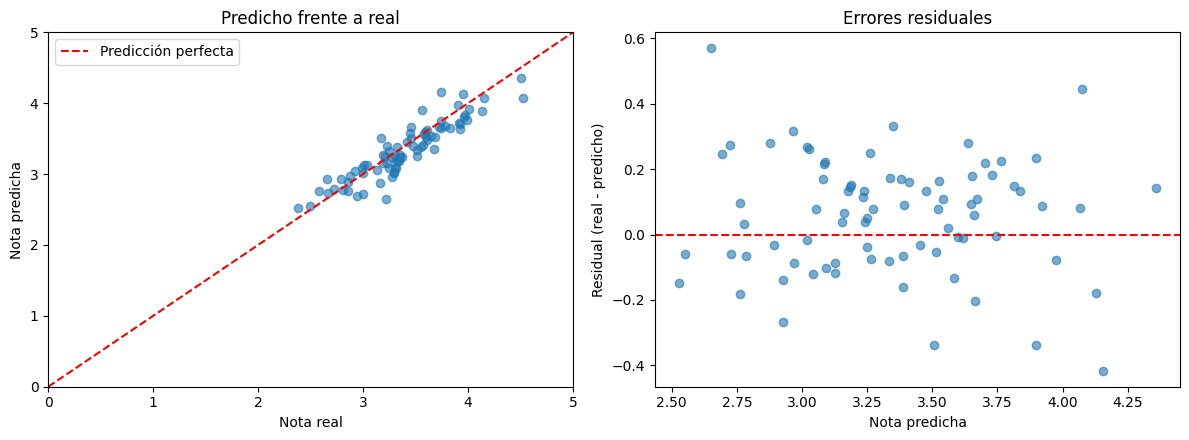

In [ ]:
# Creamos una figura con dos gráficas colocadas lado a lado.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

# IZQUIERDA: dibujamos un punto para cada estudiante de prueba.
# X = nota real; Y = nota que predijo el modelo.
ejes[0].scatter(y_prueba, y_predicho, alpha=0.6)

# Dibujamos una diagonal de referencia: allí la predicción sería perfecta.
limites = [0, 5]
ejes[0].plot(limites, limites, "r--", label="Predicción perfecta")
ejes[0].set_xlim(limites)
ejes[0].set_ylim(limites)
ejes[0].set_xlabel("Nota real")
ejes[0].set_ylabel("Nota predicha")
ejes[0].set_title("Predicho frente a real")
ejes[0].legend()

# DERECHA: calculamos el residual de cada predicción.
# Residual positivo = nota real mayor que la predicción.
residuales = y_prueba.to_numpy() - y_predicho

# Dibujamos cada predicción y su residual.
ejes[1].scatter(y_predicho, residuales, alpha=0.6)

# La línea horizontal marca un residual igual a cero.
ejes[1].axhline(0, color="r", linestyle="--")
ejes[1].set_xlabel("Nota predicha")
ejes[1].set_ylabel("Residual (real - predicho)")
ejes[1].set_title("Errores residuales")

# Ordenamos los márgenes y presentamos ambas gráficas.
plt.tight_layout()
plt.show()

## 16. Predecir las notas de tres estudiantes nuevos

Crearemos **tres casos ficticios**, sin usar notas finales conocidas. `pd.DataFrame` crea la tabla y `modelo.predict()` calcula su predicción.

**Ejemplo para leer la tabla:** `trabaja = 1` significa «sí trabaja»; `asistencia_pct = 95` significa «asiste al 95 % de las clases».

**Precaución:** estos resultados son un ejemplo didáctico con datos simulados; **no deben emplearse para calificar o decidir sobre estudiantes reales**.

In [ ]:
# Creamos tres estudiantes hipotéticos con las mismas cuatro entradas
# que el modelo utilizó durante el entrenamiento.
nuevos = pd.DataFrame({
    "promedio_anterior": [4.30, 3.10, 3.60],
    "horas_estudio_semana": [15.0, 4.0, 9.0],
    "asistencia_pct": [95.0, 62.0, 85.0],
    "trabaja": [0, 1, 1]
})

# Reordenamos las columnas exactamente como el modelo las conoció.
nuevos = nuevos[caracteristicas]

# Añadimos una columna nueva con las notas que estima la regresión.
nuevos["nota_predicha"] = modelo.predict(nuevos).round(2)

# Mostramos los tres estudiantes con su predicción.
print(nuevos.to_string(index=False))

 promedio_anterior  horas_estudio_semana  asistencia_pct  trabaja  nota_predicha
               4.3                  15.0            95.0        0           4.35
               3.1                   4.0            62.0        1           2.38
               3.6                   9.0            85.0        1           3.21


## 17. Actividad para los estudiantes

Responde usando tus resultados, no números inventados:

1. ¿Cuántas filas y columnas contiene el CSV? ¿Qué significa cada una?
2. ¿Qué es `X` y qué es `y`? Escribe el nombre de sus columnas.
3. ¿Para qué se reservan 80 estudiantes? ¿Por qué no deben estar en entrenamiento?
4. Explica `modelo.fit()` y `modelo.predict()` como se lo explicarías a un compañero que no conoce Python.
5. Escribe el MAE y el R² que te aparecieron. Interprétalos con palabras.
6. ¿El modelo lineal supera al modelo que predice siempre la media? Justifica con los dos MAE.
7. Observa las dos gráficas: ¿hay puntos muy lejos de la diagonal? ¿Hay un patrón claro en los residuales?
8. Modifica las horas de estudio de uno de los tres estudiantes nuevos, vuelve a ejecutar la última celda y explica qué cambia.

**Recuerda:** la base fue creada por simulación. Una relación estadística aquí no demuestra causalidad ni es evidencia sobre alumnos reales.

## Referencias de consulta

- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- pandas development team. (s. f.). *pandas.read_csv*. https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- scikit-learn developers. (s. f.). *LinearRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

**Procedencia de la base:** generación sintética para este ejercicio; no se extrajo de un estudio empírico ni del CSV original del repositorio.